In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

base = pd.read_csv("../data/tratado/base_mensal.csv", parse_dates=["data"], index_col="data")

PASTA_FIG = Path("../figuras")
PASTA_FIG.mkdir(exist_ok=True)

# Paleta e estilo: fixos para todos os gráficos do projeto ficarem com a mesma cara
AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, MUTED = "#0b0b0b", "#52514e", "#898781"
FONTE = "Fonte: Banco Central do Brasil (SGS). Elaboração própria."

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": TINTA_2, "text.color": TINTA,
})

def marcar_pandemia(ax):
    """Sombreia o período da pandemia, que distorce as séries de crédito."""
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=MUTED, alpha=0.12, lw=0)

base.tail()

,selic_meta,ipca_mensal,inad_total,inad_pf,inad_pj,spread_total,ipca_12m,juro_real,selic_var_12m
data,,,,,,,,,
2026-07-01,14.25,0.07,4.88,5.80,3.32,20.85,4.44,9.39,-0.75
2026-08-01,14.00,-0.32,5.05,6.04,3.36,21.15,4.22,9.38,-1.00
2026-09-01,13.75,0.82,4.98,5.99,3.28,21.61,4.58,8.77,-1.25
2026-10-01,13.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.25
2026-11-01,13.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.25


In [2]:
base.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
selic_meta,179.0,10.07,3.82,2.00,7.00,10.75,13.75,15.00
ipca_mensal,177.0,0.46,0.37,-0.68,0.24,0.43,0.67,1.62
inad_total,177.0,3.31,0.56,2.16,2.98,3.30,3.66,5.05
inad_pf,177.0,4.06,0.70,2.89,3.63,3.97,4.27,6.04
inad_pj,177.0,2.44,0.60,1.24,2.02,2.45,2.79,4.06
spread_total,177.0,18.14,2.71,13.28,15.52,18.43,20.20,23.62
ipca_12m,166.0,5.77,2.43,1.88,4.18,5.10,6.74,12.13
juro_real,166.0,4.15,3.62,-4.35,1.85,4.34,6.92,10.78
selic_var_12m,167.0,0.43,3.48,-6.75,-2.00,0.00,2.75,9.25


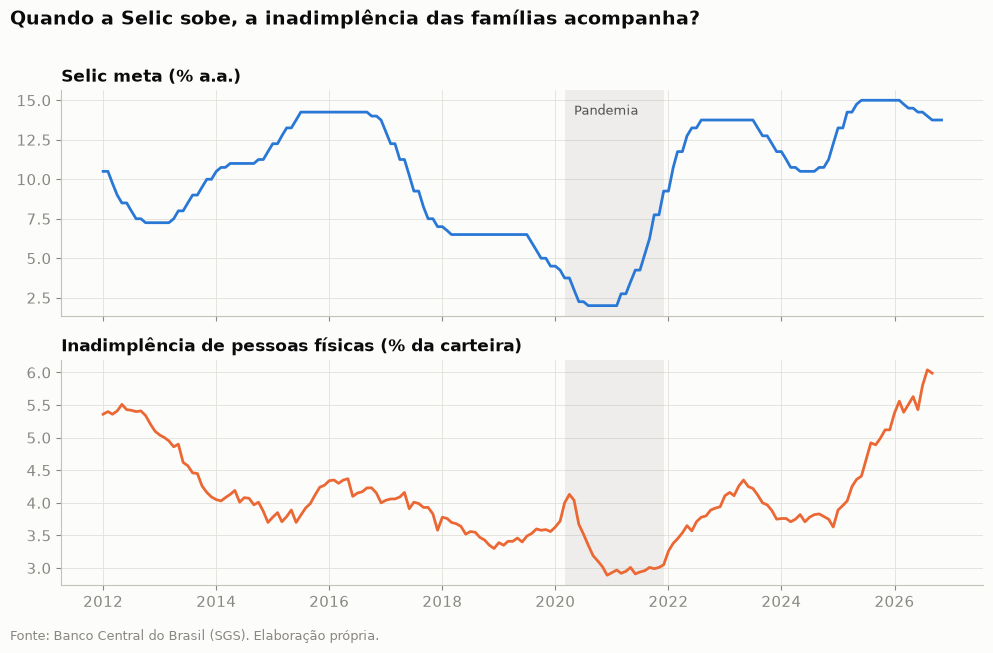

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

ax1.plot(base.index, base["selic_meta"], color=AZUL)
ax1.set_title("Selic meta (% a.a.)")

ax2.plot(base.index, base["inad_pf"], color=LARANJA)
ax2.set_title("Inadimplência de pessoas físicas (% da carteira)")

for ax in (ax1, ax2):
    marcar_pandemia(ax)
ax1.text(pd.Timestamp("2020-05-01"), ax1.get_ylim()[1] * 0.9, "Pandemia", color=TINTA_2, fontsize=9)

fig.suptitle("Quando a Selic sobe, a inadimplência das famílias acompanha?",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, FONTE, fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0.03, 1, 0.97])
fig.savefig(PASTA_FIG / "01_selic_vs_inad_pf.png", dpi=150)
plt.show()

O que aconteceu com a inadimplência durante a pandemia? Por que você acha que isso aconteceu? 
Durante a pandemia de COVID-19, o governo brasileiro criou o Auxílio Emergencial para mitigar os impactos econômicos, mas muitas pessoas destinaram esse dinheiro à quitação de dívidas antigas, facilitando a atuação das empresas de recuperação de crédito.  Embora houvesse acordos para proteger o benefício de descontos automáticos, a redução do valor do auxílio em 2021, somada à inflação e ao desemprego, fez com que 64% dos inadimplentes que renegociaram dívidas em 2020 voltassem à inadimplência em 2021. 

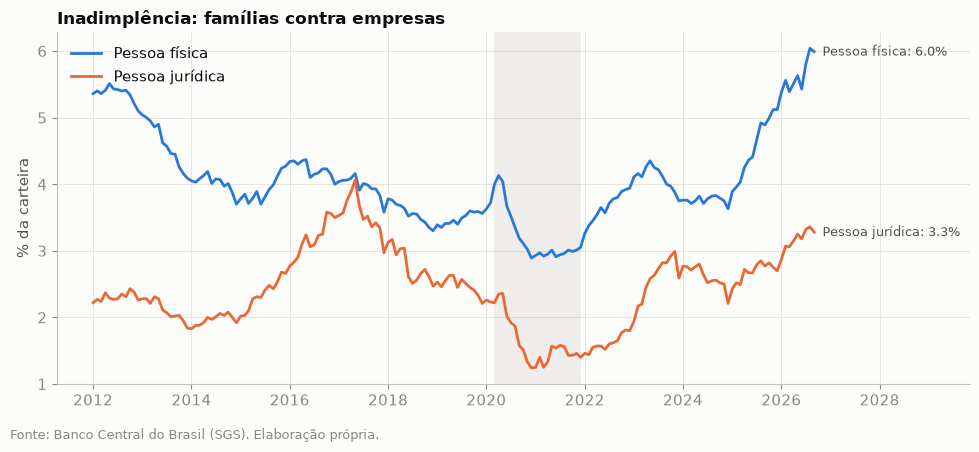

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))

for coluna, cor, rotulo in [("inad_pf", AZUL, "Pessoa física"), ("inad_pj", LARANJA, "Pessoa jurídica")]:
    serie = base[coluna].dropna()
    ax.plot(serie.index, serie, color=cor, label=rotulo)
    ax.annotate(f"{rotulo}: {serie.iloc[-1]:.1f}%", (serie.index[-1], serie.iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA_2)

marcar_pandemia(ax)
ax.set_xlim(right=base.index[-1] + pd.DateOffset(months=36))  # espaço para os rótulos
ax.set_ylabel("% da carteira")
ax.set_title("Inadimplência: famílias contra empresas")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, 0.01, FONTE, fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(PASTA_FIG / "02_inad_pf_vs_pj.png", dpi=150)
plt.show()

Quem tem a inadimplência mais alta, pessoa física ou jurídica? E qual das duas reage mais à Selic?
Hoje, as pessoas físicas possuem inadimplencia mais alta, cerca de 6% das carteiras, segundo dados do SGS.
A pessoa física é muito mais sensível à Selic, por dois motivos:

Spread maior: a taxa média cobrada da PF (38,5% a.a. em setembro/2026) tem um spread sobre a Selic muito maior que o da PJ (19,4% a.a.). Cada ponto de Selic se traduz em um aumento proporcionalmente maior nos juros do consumidor.
Mix de crédito mais caro: a PF depende de linhas (rotativo, cheque especial) cuja taxa acompanha de perto a Selic, enquanto a PJ acessa linhas mais baratas como capital de giro (~25% a.a.) e desconto de duplicatas (~25% a.a.), menos elásticas à taxa básica.
Na prática, quando a Selic sobe, a inadimplência PF reage com mais força e mais rapidez; quando cai, a melhora também é mais visível na PF — embora, como apontam economistas, a defasagem entre a Selic e os juros efetivamente cobrados seja grande o suficiente para que a queda da Selic não resolva sozinha o problema de inadimplência das famílias.

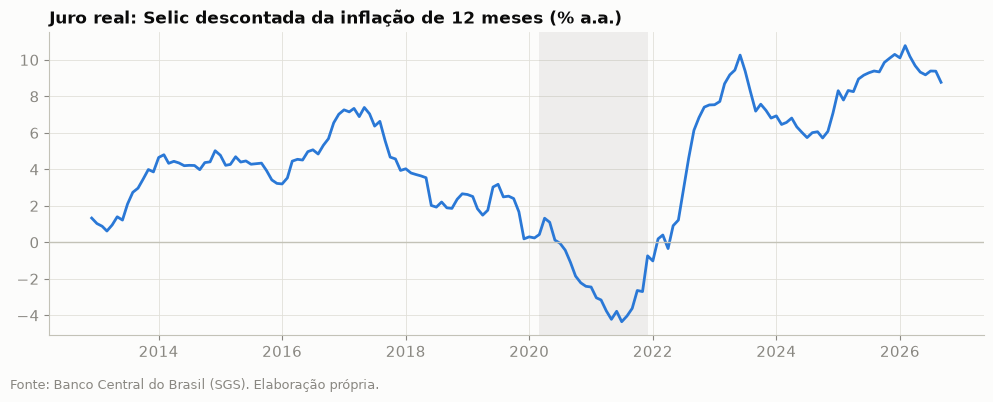

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
serie = base["juro_real"].dropna()
ax.plot(serie.index, serie, color=AZUL)
ax.axhline(0, color="#c3c2b7", lw=1)
marcar_pandemia(ax)
ax.set_title("Juro real: Selic descontada da inflação de 12 meses (% a.a.)")
fig.text(0.01, 0.01, FONTE, fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(PASTA_FIG / "03_juro_real.png", dpi=150)
plt.show()

Em quais anos o juro real esteve mais alto? Hoje ele está alto ou baixo em relação ao histórico?
Hoje ele é alto em relação ao historico. 
O que chama atenção é a gradativa elevação no pós pandemia. Até 2023, pós isso ele começa a recuar até 2025, aumentando novamente em 2026.
O Copom se reúne nesta quarta (4/11) e o mercado aposta em pausa em 13,75%. Se a Selic cair para 13,25% em dezembro, o juro real cairia para ~8,5–9%. Para voltar ao patamar de 2010 (~3–4%), a Selic precisaria chegar a algo em torno de 8–9%, o que exigiria inflação ancorada e trajetória fiscal sustentável — um horizonte de anos, não meses.

In [6]:
# 1. Juro real: ano a ano (média) e o mês de pico
juro_ano = base["juro_real"].groupby(base.index.year).mean().round(2)
print("Juro real médio por ano:\n", juro_ano.to_string())
print(f"\nPico: {base['juro_real'].max():.2f}% em {base['juro_real'].idxmax():%m/%Y}")

# 2. Inadimplência antes, durante e depois da pandemia
print("\nInadimplência PF e PJ (dezembro de cada ano):")
print(base.loc[base.index.month == 12, ["inad_pf", "inad_pj"]].loc["2018":"2023"].to_string())

# 3. Mínimos e máximos da inadimplência PF
print(f"\nInad. PF mínima: {base['inad_pf'].min():.2f}% em {base['inad_pf'].idxmin():%m/%Y}")
print(f"Inad. PF máxima: {base['inad_pf'].max():.2f}% em {base['inad_pf'].idxmax():%m/%Y}")

Juro real médio por ano:
 data
2012    1.33
2013    2.10
2014    4.42
2015    4.19
2016    4.97
2017    6.24
2018    2.80
2019    2.14
2020   -0.38
2021   -3.21
2022    3.07
2023    8.27
2024    6.32
2025    9.09
2026    9.65

Pico: 10.78% em 02/2026

Inadimplência PF e PJ (dezembro de cada ano):
            inad_pf  inad_pj
data                        
2018-12-01     3.30     2.47
2019-12-01     3.56     2.21
2020-12-01     2.89     1.24
2021-12-01     3.05     1.40
2022-12-01     3.94     1.80
2023-12-01     3.75     2.59

Inad. PF mínima: 2.89% em 12/2020
Inad. PF máxima: 6.04% em 08/2026


In [7]:
base.loc["2024-09":"2025-06", ["inad_pf", "inad_pj", "inad_total"]]

,inad_pf,inad_pj,inad_total
data,,,
2024-09-01,3.83,2.56,3.34
2024-10-01,3.79,2.52,3.30
2024-11-01,3.75,2.50,3.27
2024-12-01,3.63,2.21,3.08
2025-01-01,3.89,2.43,3.34
2025-02-01,3.96,2.52,3.41
2025-03-01,4.03,2.49,3.44
2025-04-01,4.25,2.72,3.67
2025-05-01,4.36,2.67,3.72


In [8]:
# Variação média da inadimplência PF em cada mês do ano (2012–2026)
variacao = base["inad_pf"].diff()
variacao.groupby(variacao.index.month).mean().round(2)

data
1     0.10
2     0.04
3    -0.01
4     0.06
5     0.06
6    -0.16
7     0.07
8     0.02
9    -0.02
10   -0.01
11   -0.04
12   -0.08
Name: inad_pf, dtype: float64

# Análise exploratória — Selic e inadimplência no Brasil (2012–2026)

## Pergunta de negócio
**Quando a Selic sobe, a inadimplência das famílias sobe também? Com quanto tempo de defasagem?**
A resposta interessa a bancos e financeiras porque orienta a política de concessão de crédito e o
cálculo da provisão para perdas (que, pela IFRS 9 / Resolução CMN 4.966, deve considerar cenários
macroeconômicos futuros).

## Dados e tratamento
- **Fonte:** Banco Central do Brasil — SGS (Sistema Gerenciador de Séries Temporais), via API pública.
- **Séries:** Selic meta (432), IPCA mensal (433), inadimplência total (21082), PJ (21083) e PF (21084),
  spread médio (20783). Período: jan/2012 a set/2026 (crédito) e nov/2026 (Selic).
- **Arquitetura em camadas:** `data/bruto` (dado como veio da API) → `data/tratado` (base mensal).
- **Decisões de tratamento:**
  - Selic é diária → usado o valor vigente no último dia de cada mês.
  - IPCA 12 meses calculado por juros compostos (produto de 1 + taxa), não por soma.
  - Juro real **ex-post** pela equação de Fisher: (1 + Selic) / (1 + IPCA 12m) − 1.
  - Valores faltantes explicados: os dados de crédito são divulgados com ~2 meses de defasagem, e
    indicadores de 12 meses precisam de 12 meses de histórico.

## Resumo dos achados
1. A inadimplência PF reage à Selic **com defasagem de alguns meses**, não imediatamente.
2. A pandemia derrubou a inadimplência PF à **mínima da série (2,89% em dez/2020)** — queda artificial,
   sustentada por carências, renegociações e auxílio emergencial.
3. A inadimplência PF é quase o **dobro da PJ** e subiu **duas vezes mais** no ciclo de alta de 2024–2025.
4. O juro real atingiu **10,78% em fev/2026**, o maior da série, e segue mais que o dobro da média
   histórica (~4%).
5. Não há evidência de quebra abrupta na série com a Resolução CMN 4.966, mas há **sazonalidade
   relevante** (quedas em junho e dezembro) que precisa ser tratada na modelagem.

---

## 1. A inadimplência acompanha a Selic?
**O dado mostra:** no ciclo mais recente, a Selic começou a subir em set/2024 (a partir de 10,5%, até
15% em 2025), enquanto a inadimplência PF permaneceu estável até o início de 2025 e acelerou a partir de
abr/2025 (de 4,03% em mar/2025 para 4,25% em abr/2025, chegando a 6,04% em ago/2026, o máximo da série).
O efeito aparece cerca de 6 a 7 meses depois do início do aperto monetário.

**Interpretação:** o efeito dos juros é defasado. Contratos antigos têm taxa travada; o aperto chega
primeiro nas novas concessões e nas linhas rotativas, e leva meses para se transformar em atraso acima
de 90 dias.

🔲 **A testar no Passo 7:** medir a defasagem com correlação defasada (lags de 0 a 18 meses).

## 2. O que aconteceu na pandemia?
**O dado mostra:** a inadimplência PF caiu de 3,56% em dez/2019 para 2,89% em dez/2020 — a mínima de
toda a série — e voltou a subir nos anos seguintes (3,75% em dez/2023).

**Interpretação:** a queda foi artificial. Prorrogações e carências de parcelas autorizadas pelo CMN,
o auxílio emergencial e a menor concessão de crédito de maior risco seguraram os atrasos. Com a redução
do auxílio em 2021, a inflação alta e o ciclo de alta da Selic, a inadimplência voltou a subir.
Levantamentos de mercado apontaram que boa parte de quem renegociou dívidas em 2020 voltou à
inadimplência em 2021 [citar fonte: Serasa/CNDL, data].

**Implicação:** 2020–2021 é um período atípico (quebra estrutural) e deve ser tratado à parte ou
excluído em análises estatísticas.

## 3. Pessoa física × pessoa jurídica
**O dado mostra:** a inadimplência PF (5,99% em set/2026) é quase o dobro da PJ (3,28%), e a diferença
se mantém em todo o período. No ciclo de alta recente (nov/2024 → set/2026, comparando com novembro para
evitar a queda sazonal de dezembro):

| | nov/2024 | set/2026 | Variação |
|---|---|---|---|
| PF | 3,75% | 5,99% | +2,24 p.p. (+60%) |
| PJ | 2,50% | 3,28% | +0,78 p.p. (+31%) |

**Interpretação:** famílias têm menos colchão financeiro, dependem mais de linhas caras e sem garantia
(rotativo, cheque especial, crédito pessoal) e sentem diretamente desemprego e renda comprometida com
dívidas. Já o crédito PJ é em boa parte pós-fixado (CDI + spread): o **custo** reage rápido à Selic,
mas a **inadimplência** reage menos, porque empresas têm mais garantias e capacidade de renegociar.

🔲 **A testar no Passo 7:** se a PF é estatisticamente mais sensível à Selic do que a PJ.

## 4. Juro real: em quais anos foi mais alto? Hoje é alto ou baixo?
**O dado mostra:** o juro real ex-post atingiu **10,78% em fev/2026**, o maior nível da série. As
maiores médias anuais foram 2026 (9,65%, jan–set) e 2025 (9,09%). A trajetória:

- **2020–2021:** negativo (−3,21% em 2021) — Selic a 2% com inflação acima de 10%;
- **2022–2023:** alta forte (3,07% → 8,27%) com a Selic indo a 13,75%;
- **2024:** recuo (6,32%) com cortes da Selic;
- **2025–fev/2026:** nova alta (9,09% em 2025) com a Selic indo a 15% e a inflação desacelerando;
- **desde fev/2026:** queda (9,39% em jul → 8,77% em set), ainda **mais que o dobro da média do
  período (~4%)**.

**Interpretação:** a inflação de 12 meses convergiu para 4,58%, mas a Selic recua devagar (de 15% para
13,75%). A política monetária segue apertada — o que ajuda a explicar a inadimplência PF perto de 6%.

**Cenário:** com inflação de ~4,5%, levar o juro real a ~3,5% exigiria Selic perto de 8%
(1,035 × 1,045 − 1 ≈ 8,2%). Isso depende de expectativas de inflação ancoradas e de uma trajetória
fiscal crível; a incerteza fiscal mantém juros longos e expectativas elevadas, levando o Copom a cortar
com cautela [fonte: Boletim Focus / atas do Copom, data]. É um processo de anos, não de meses.

*Notas: 2012 tem apenas 1 mês de juro real (dez), pois o IPCA 12m exige 12 meses de histórico; 2026
cobre jan–set. O juro real ex-post usa a inflação passada; o mercado também acompanha o ex-ante
(inflação esperada).*

---

## 5. Qualidade dos dados

### Há quebra de série com a Resolução CMN 4.966 (jan/2025)?
**Resultado:** não há evidência de quebra abrupta. A alta de dez/2024 para jan/2025 (+0,26 p.p.) reflete
a queda sazonal de dezembro, que também aparece na série PJ (2,50% → 2,21% → 2,43%). Comparando jan/2025
com nov/2024, a variação é de apenas +0,14 p.p. Depois disso, a alta é gradual (3,89% → 4,41% até
jun/2025) e coerente com o ciclo da Selic.

*Ressalva: a ausência de salto não prova ausência de efeito metodológico; a mudança de regra fica
registrada como limitação.*

### Sazonalidade
**O dado mostra:** variação média mensal da inadimplência PF (2012–2026):
janeiro **+0,10 p.p.** (maior alta), junho **−0,16 p.p.** (maior queda) e dezembro **−0,08 p.p.**

**Interpretação:** junho e dezembro coinc
idem com os fechamentos semestrais de balanço, quando os
bancos tendem a lançar créditos antigos a prejuízo, e dezembro tem ainda o efeito do 13º salário.
Parte dessas quedas é **contábil**, não melhora real; a alta de janeiro é, em grande parte, a reversão
de dezembro.

🔲 **A verificar:** se a queda de junho é consistente entre os anos ou puxada por um ano atípico (usar
mediana).

**Implicação:** nas análises seguintes, usar média móvel de 3 meses ou variação em 12 meses.

---

## Limitações
- Correlação não implica causalidade: a inadimplência também depende de emprego, renda, endividamento
  das famílias e programas como o Desenrola (2023–2024), não controlados nesta análise.
- Os dados de crédito têm ~2 meses de defasagem de divulgação.
- O período 2020–2021 é atípico, e a Resolução CMN 4.966 (2025) pode afetar a comparabilidade.
- O juro real é ex-post (inflação passada), não ex-ante.

## Hipóteses para a próxima etapa (Passo 7)
1. A correlação entre Selic e inadimplência PF é máxima com defasagem entre 6 e 12 meses.
2. A inadimplência PF é mais sensível à Selic do que a PJ.
3. Os resultados se mantêm ao excluir o período 2020–2021.